Name : Aishi De Sec : A Sem : 7 PRN : 23070521008 Batch : A1


AIM : Convolutional Autoencoder on MNIST Dataset. Problem Statement: Implement a
Convolutional Autoencoder to learn compressed image representations and reconstruct
handwritten digits. Activities: Build encoder-decoder architecture; Train autoencoder;
Compare original and reconstructed images.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# Load MNIST dataset
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values to [0, 1] and reshape to (28, 28, 1)
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = np.reshape(x_train, (-1, 28, 28, 1))
x_test = np.reshape(x_test, (-1, 28, 28, 1))

print(f"Training shape: {x_train.shape}")
print(f"Test shape: {x_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


In [ ]:
# --- ENCODER ---
input_img = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2, 2), padding='same')(x)  # 28x28 -> 14x14
x = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)  # 14x14 -> 7x7
x = layers.Conv2D(8, (3, 3), activation='relu', padding='same')(x)
encoded = layers.MaxPooling2D((2, 2), padding='same', name='bottleneck')(x)  # 7x7 -> 4x4x8

# --- DECODER ---
x = layers.Conv2D(8, (3, 3), activation='relu', padding='same')(encoded)
x = layers.UpSampling2D((2, 2))(x)                  # 4x4 -> 8x8
x = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)                  # 8x8 -> 16x16
x = layers.Conv2D(32, (3, 3), activation='relu')(x) # 16x16 -> 14x14
x = layers.UpSampling2D((2, 2))(x)                  # 14x14 -> 28x28
decoded = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x) # 28x28x1

# Compile model
autoencoder = models.Model(input_img, decoded)
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 8)        │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (MaxPooling2D)       │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 16)       │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,785 (49.94 KB)

 Trainable params: 12,785 (49.94 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=128,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 103s 214ms/step - loss: 0.1950 - val_loss: 0.1320
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 105s 224ms/step - loss: 0.1235 - val_loss: 0.1151
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 102s 218ms/step - loss: 0.1129 - val_loss: 0.1087
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 141s 217ms/step - loss: 0.1078 - val_loss: 0.1047
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 100s 213ms/step - loss: 0.1045 - val_loss: 0.1023
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 142s 213ms/step - loss: 0.1021 - val_loss: 0.0996
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 143s 216ms/step - loss: 0.1002 - val_loss: 0.0981
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 142s 217ms/step - loss: 0.0985 - val_loss: 0.0966
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 101s 214ms/step - loss: 0.0973 - val_loss: 0.0957
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 141s 213ms/step - loss: 0.0961 - val_loss: 0.0946


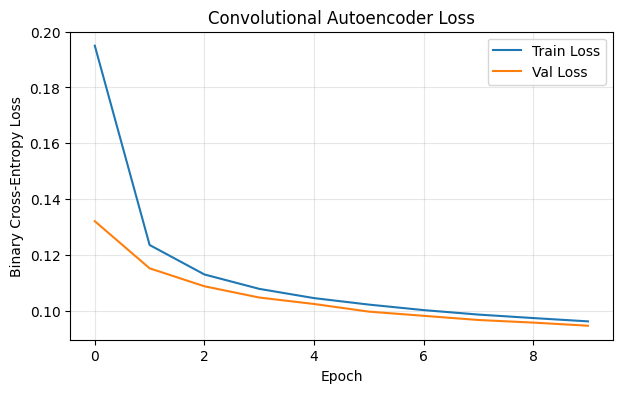

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Convolutional Autoencoder Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step


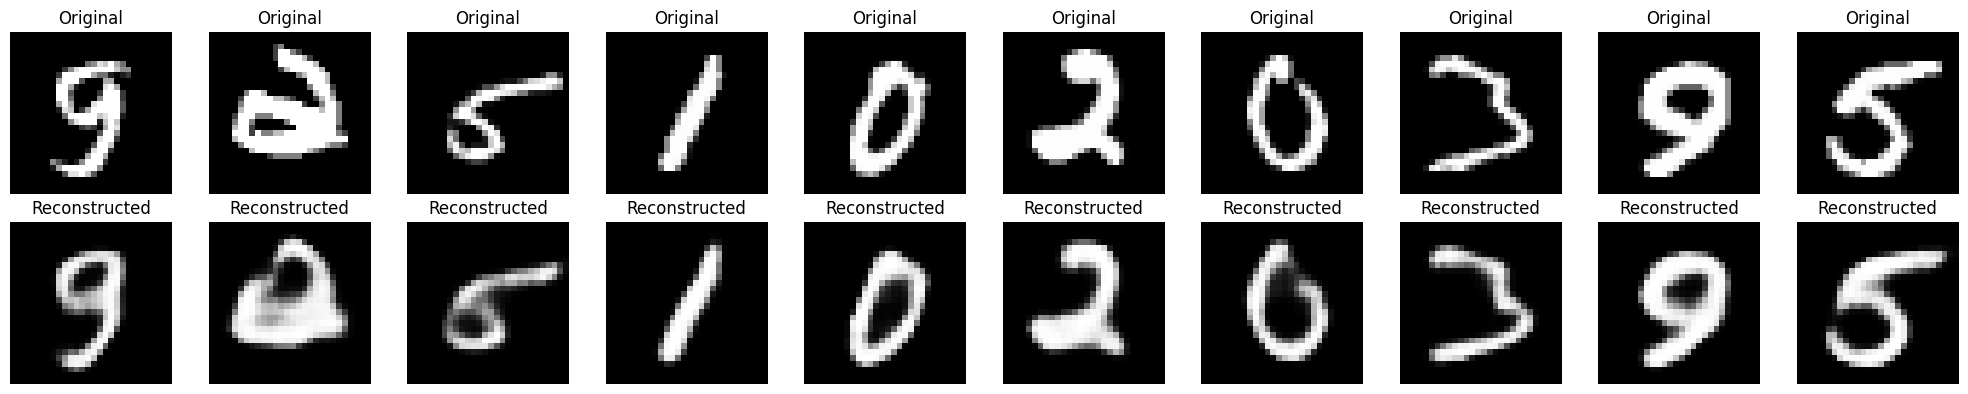

In [ ]:
reconstructed_imgs = autoencoder.predict(x_test)

n = 10
indices = np.random.choice(len(x_test), n, replace=False)

plt.figure(figsize=(20, 4))
for i, idx in enumerate(indices):
    # Original Images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed Images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_imgs[idx].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()